## 2. CPI target inspection

[![content: AI-generated](../_static/badges/ai-generated.svg)](ai-acknowledgement) [![content: human-reviewed & edited](../_static/badges/human-reviewed-edited.svg)](ai-acknowledgement)

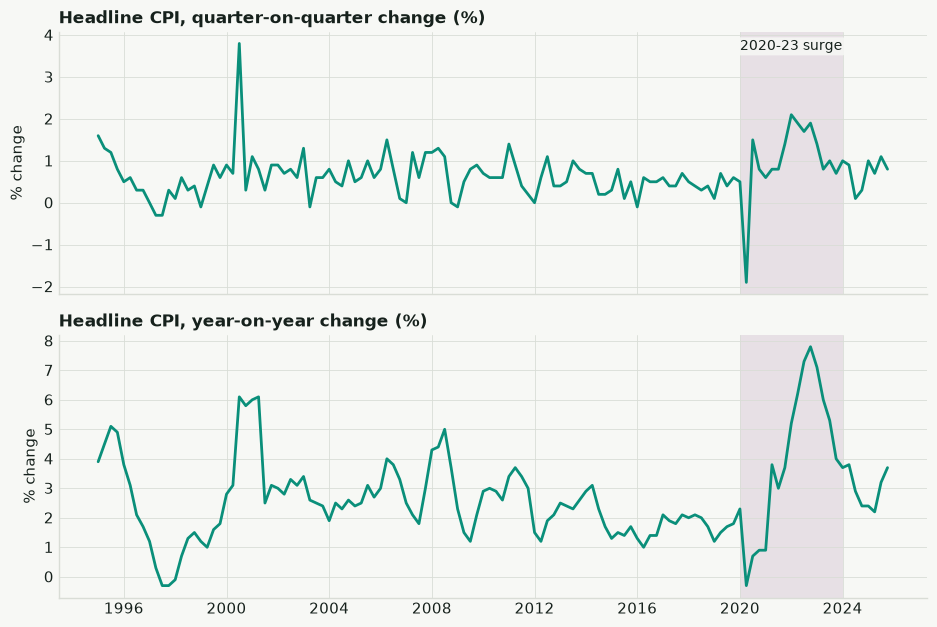

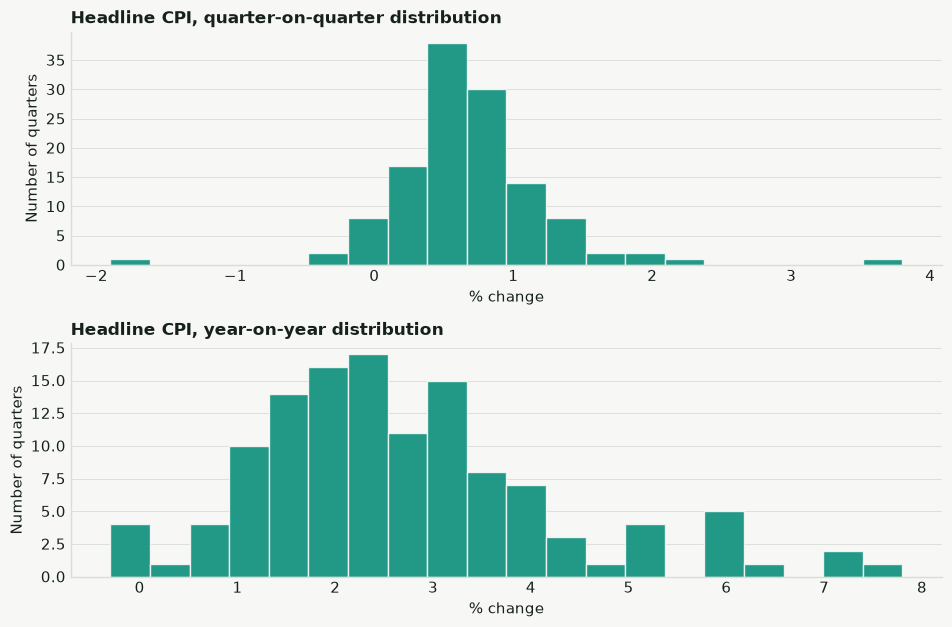

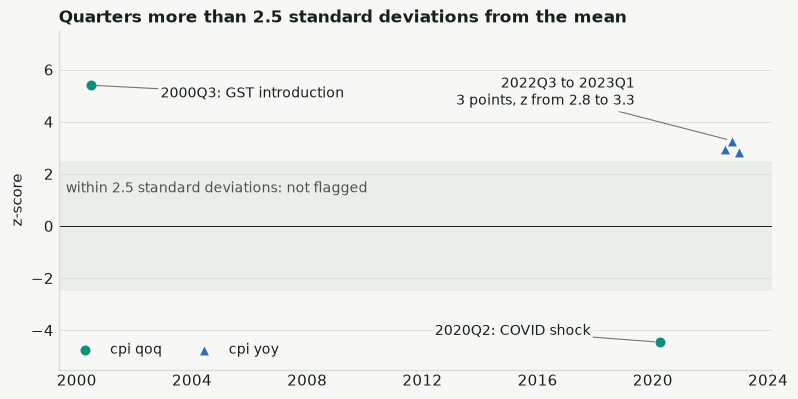

In [5]:
plot_specs = [
    ('cpi_qoq', 'Headline CPI, quarter-on-quarter change (%)', ACCENT),
    ('cpi_yoy', 'Headline CPI, year-on-year change (%)', ACCENT),
]

def shade_surge(ax, label=False, where="top", alpha=0.14):
    """The 2020-23 COVID and inflation-surge window as one light full-height band: one definition for the whole book.
    label=True names the band in plain text (do that once per figure); `where` is "top" or "bottom"."""
    s, e = pd.Period("2020Q1", "Q").to_timestamp(), pd.Period("2023Q4", "Q").to_timestamp(how="end")
    ax.axvspan(s, e, color="#8a4f8a", alpha=alpha, linewidth=0, zorder=0)
    if label:
        ax.text(s + (e - s) / 2, 0.97 if where == "top" else 0.03, "2020-23 surge", transform=ax.get_xaxis_transform(),
                ha="center", va="top" if where == "top" else "bottom", fontsize=10, color="#16211c", zorder=1.6,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="#f7f8f5", edgecolor="none", alpha=0.85))

with plt.rc_context(BOOK_STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.4), sharex=True)
    for ax, (column, title, color) in zip(axes, plot_specs):
        ax.plot(df['quarter_start'], df[column], color=color, linewidth=2.0)
        ax.set_title(title)
        ax.set_ylabel('% change')
        shade_surge(ax, label=(ax is axes[0]), where="top")
    fig.tight_layout()
    plt.show()

with plt.rc_context(BOOK_STYLE):
    fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.4))
    for ax, (column, title, color) in zip(axes, plot_specs):
        df[column].dropna().hist(ax=ax, bins=20, color=color, alpha=0.9, edgecolor=PAPER)
        ax.set_title(title.replace('change (%)', 'distribution'))
        ax.set_xlabel('% change')
        ax.set_ylabel('Number of quarters')
        ax.grid(axis='x', visible=False)
    fig.tight_layout()
    plt.show()

outlier_rows = []
for column, _, _ in plot_specs:
    series = df[column]
    z_score = (series - series.mean()) / series.std(ddof=0)
    flagged = df.loc[z_score.abs() >= 2.5, ['quarter', column]].copy()
    flagged['metric'] = column
    flagged['z_score'] = z_score.loc[flagged.index].round(2)
    outlier_rows.append(flagged[['quarter', 'metric', column, 'z_score']].rename(columns={column: 'value'}))
outliers = pd.concat(outlier_rows, ignore_index=True) if outlier_rows else pd.DataFrame()
with plt.rc_context(BOOK_STYLE):
    z = outliers.copy()
    z["date"] = pd.PeriodIndex(z["quarter"], freq="Q").to_timestamp()
    styles = {"cpi_qoq": (ACCENT, "o"), "cpi_yoy": (BLUE, "^")}
    fig, ax = plt.subplots(figsize=(9.2, 4.4))
    ax.axhspan(-2.5, 2.5, color=GRID, alpha=0.4, linewidth=0)
    ax.text(0.01, 1.3, "within 2.5 standard deviations: not flagged", transform=ax.get_yaxis_transform(), fontsize=10, color=INK, alpha=0.75)
    ax.axhline(0, color=INK, linewidth=0.7)
    for metric, sub in z.groupby("metric"):
        colour, marker = styles.get(metric, (MUTED, "o"))
        ax.scatter(sub["date"], sub["z_score"], s=70, color=colour, marker=marker, edgecolor=PAPER, linewidth=1.2,
                   label=metric.replace("_", " "), zorder=3)
    leader = dict(arrowstyle="-", color=INK, alpha=0.6, linewidth=0.8, shrinkA=0, shrinkB=4)
    box = dict(boxstyle="round,pad=0.15", facecolor=PAPER, edgecolor="none", alpha=0.9)
    cluster = z[z["date"] >= "2021-01-01"]
    for _, r in z[z["date"] < "2021-01-01"].iterrows():
        up = r["z_score"] > 0
        ax.annotate(f"{r['quarter']}: {'GST introduction' if r['quarter'] == '2000Q3' else 'COVID shock'}", (r["date"], r["z_score"]),
                    xytext=(50 if up else -50, -6 if up else 8), textcoords="offset points",
                    ha="left" if up else "right", va="center", fontsize=10, bbox=box, arrowprops=leader)
    ax.annotate(f"{cluster['quarter'].min()} to {cluster['quarter'].max()}" + chr(10) + f"{len(cluster)} points, z from {cluster['z_score'].min():.1f} to {cluster['z_score'].max():.1f}",
                (cluster["date"].mean(), cluster["z_score"].max()), xytext=(-70, 26), textcoords="offset points",
                ha="right", fontsize=10, bbox=box, arrowprops=leader)
    ax.set_ylabel("z-score")
    ax.set_ylim(-5.5, 7.5)
    ax.set_title("Quarters more than 2.5 standard deviations from the mean", loc="left", fontsize=12.5, fontweight="bold")
    ax.legend(frameon=False, fontsize=10, loc="lower left", ncol=2)
    ax.grid(axis="x", visible=False)
    plt.show()

### CPI seasonal decomposition and autocorrelation diagnostics

These diagnostics extend the CPI target inspection. STL separates the CPI index into trend, quarterly seasonal, and residual components; ACF/PACF plots then show whether CPI inflation and differenced CPI retain serial dependence that later SARIMA order selection should consider.

The modelling target `cpi_yoy` is already a four-quarter transformation: `CPI_YoY_t = (CPI_t / CPI_{t-4} - 1) * 100`. Adjacent YoY observations share overlapping CPI observations, so persistence in the ACF is partly mechanical and shouldn't be read as purely an autoregressive economic mechanism. Quarterly data also doesn't automatically imply `D = 1`; seasonal and non-seasonal SARIMA specifications should be compared with rolling-origin validation.

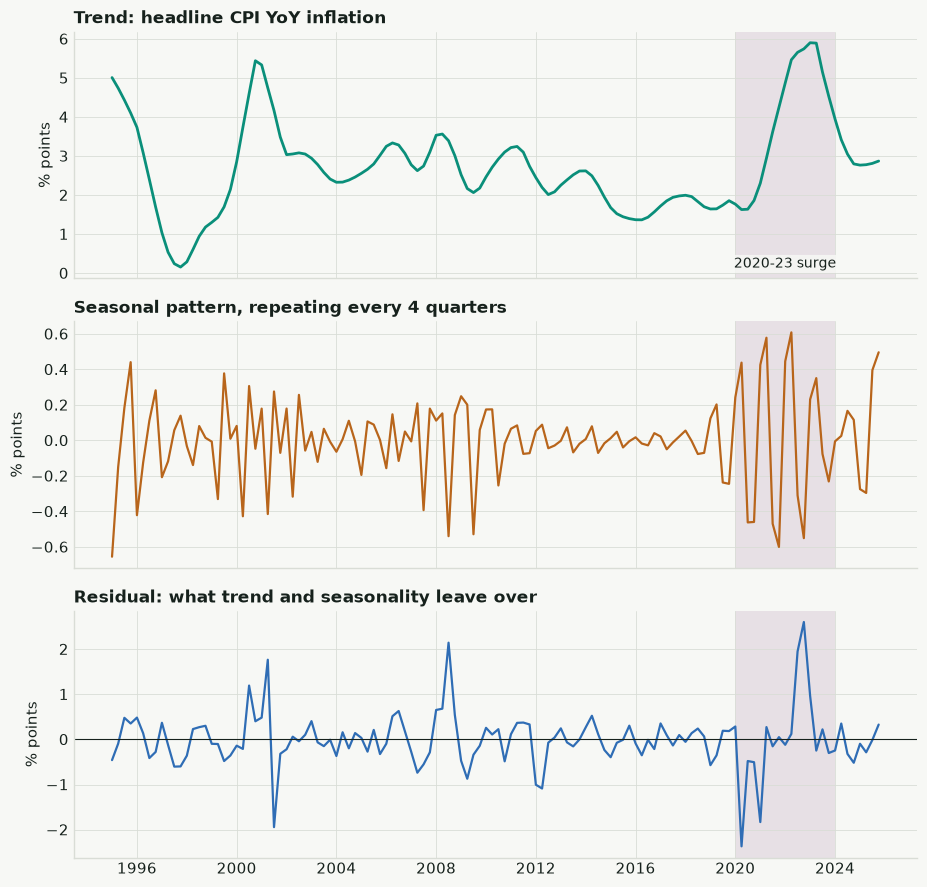

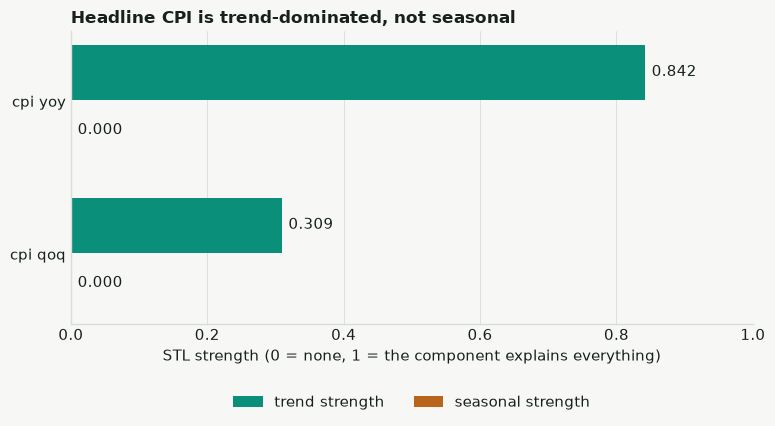

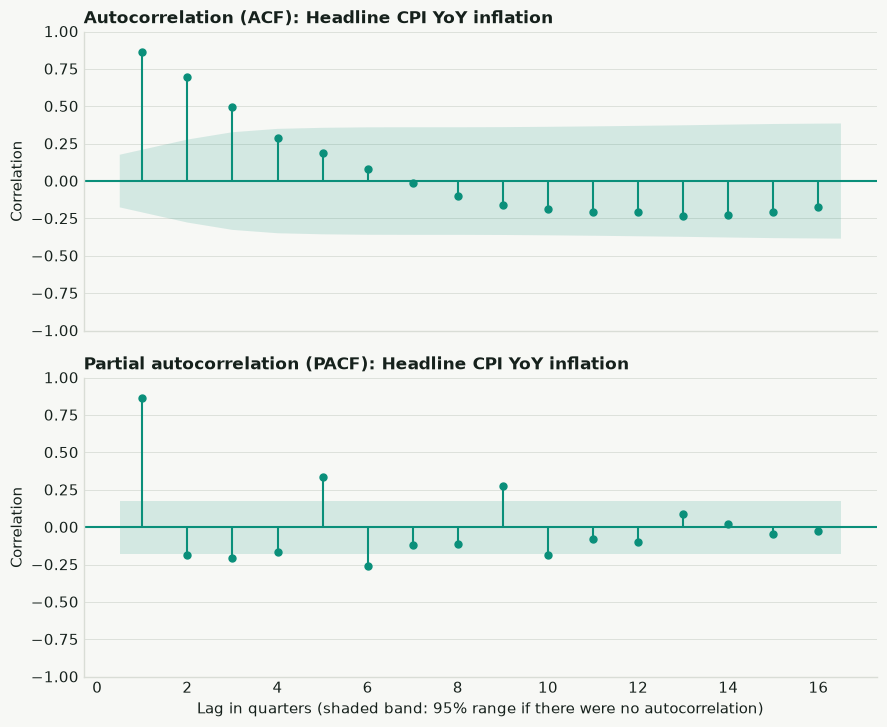

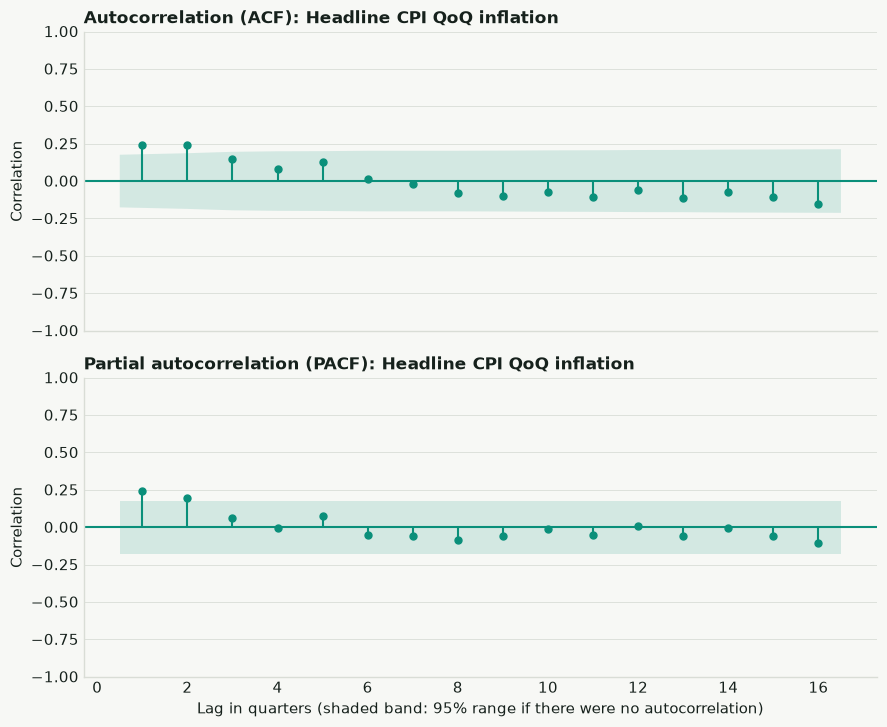

In [6]:
def stl_strength_summary(series: pd.Series, label: str) -> dict[str, object]:
    cleaned = series.dropna()
    result = STL(cleaned, period=4, robust=True).fit()
    seasonal_strength = max(0, 1 - np.nanvar(result.resid) / np.nanvar(result.resid + result.seasonal))
    trend_strength = max(0, 1 - np.nanvar(result.resid) / np.nanvar(result.resid + result.trend))
    return {
        'series': label,
        'stl_period_quarters': 4,
        'seasonal_strength': seasonal_strength,
        'trend_strength': trend_strength,
        'n_obs': int(len(cleaned)),
        'stl_result': result,
    }

cpi_stl_series = df.set_index('quarter_start')['cpi_yoy'].dropna()
stl_result = STL(cpi_stl_series, period=4, robust=True).fit()

with plt.rc_context(BOOK_STYLE):
    fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)
    axes[0].plot(stl_result.trend.index, stl_result.trend, color=ACCENT, linewidth=2.0)
    axes[0].set_title('Trend: headline CPI YoY inflation')
    axes[1].plot(stl_result.seasonal.index, stl_result.seasonal, color=HIGHLIGHT, linewidth=1.6)
    axes[1].set_title('Seasonal pattern, repeating every 4 quarters')
    axes[2].plot(stl_result.resid.index, stl_result.resid, color=BLUE, linewidth=1.6)
    axes[2].axhline(0, color=INK, linewidth=0.8)
    axes[2].set_title('Residual: what trend and seasonality leave over')
    for ax in axes:
        ax.set_ylabel('% points')
        shade_surge(ax, label=(ax is axes[0]), where="bottom")
    fig.tight_layout()
    plt.show()

stl_strength_rows = [
    stl_strength_summary(df.set_index('quarter_start')[column], column)
    for column in ['cpi_yoy', 'cpi_qoq']
]
seasonality_summary = pd.DataFrame([
    {key: value for key, value in row.items() if key != 'stl_result'}
    for row in stl_strength_rows
])
seasonality_summary['interpretation'] = np.select(
    [
        seasonality_summary['series'].eq('cpi_yoy'),
        seasonality_summary['series'].str.endswith('_qoq'),
    ],
    [
        'STL now decomposes the ABS SA headline growth-rate target, not a CPI level index.',
        'QoQ seasonality is closer to the quarterly inflation-rate series used in differenced SARIMA diagnostics.',
    ],
    default='',
)
with plt.rc_context(BOOK_STYLE):
    s = seasonality_summary.iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.8, 3.8))
    ax.barh(s.index + 0.19, s["trend_strength"], height=0.36, color=ACCENT, label="trend strength")
    ax.barh(s.index - 0.19, s["seasonal_strength"], height=0.36, color=HIGHLIGHT, label="seasonal strength")
    for y, r in s.iterrows():
        ax.text(r["trend_strength"] + 0.01, y + 0.19, f"{r['trend_strength']:.3f}", va="center", fontsize=10.5)
        ax.text(r["seasonal_strength"] + 0.01, y - 0.19, f"{r['seasonal_strength']:.3f}", va="center", fontsize=10.5)
    ax.set_yticks(s.index, s["series"].str.replace("_", " "), fontsize=10.5)
    ax.set_xlim(0, 1)
    ax.set_xlabel("STL strength (0 = none, 1 = the component explains everything)")
    ax.set_title("Headline CPI is trend-dominated, not seasonal", loc="left", fontsize=12.5, fontweight="bold")
    ax.legend(frameon=False, fontsize=10.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax.grid(axis="y", visible=False)
    plt.show()

acf_pacf_series = {
    'Headline CPI YoY inflation': df.set_index('quarter_start')['cpi_yoy'].dropna(),
    'Headline CPI QoQ inflation': df.set_index('quarter_start')['cpi_qoq'].dropna(),
}

from matplotlib.collections import PolyCollection

for title, series in acf_pacf_series.items():
    with plt.rc_context(BOOK_STYLE):
        fig, axes = plt.subplots(2, 1, figsize=(9, 7.4), sharex=True)
        safe_lags = min(16, max(1, len(series) // 2 - 1))
        plot_acf(series, lags=safe_lags, ax=axes[0], zero=False, color=ACCENT, vlines_kwargs={'colors': ACCENT})
        plot_pacf(series, lags=safe_lags, ax=axes[1], zero=False, method='ywm', color=ACCENT, vlines_kwargs={'colors': ACCENT})
        axes[0].set_title(f'Autocorrelation (ACF): {title}')
        axes[1].set_title(f'Partial autocorrelation (PACF): {title}')
        axes[0].set_ylabel('Correlation')
        axes[1].set_ylabel('Correlation')
        axes[1].set_xlabel('Lag in quarters (shaded band: 95% range if there were no autocorrelation)')
        for ax in axes:
            ax.grid(axis='x', visible=False)
            for artist in ax.collections:
                if isinstance(artist, PolyCollection):
                    artist.set_facecolor(ACCENT)
                    artist.set_alpha(0.15)
        fig.tight_layout()
        plt.show()


**Interpretation.** The flagged extreme quarters aren't statistical noise. They map
directly onto known events: 2000Q3 (`cpi_qoq` z=5.41) is the GST introduction, 2020Q2
(z=-4.45) is the COVID demand shock, and the 2022Q3 to 2023Q1 run (z=2.8–3.3 on year-on-year
headline CPI) is the post-COVID inflation surge. That's a useful cross-check on [§3 Data
Preparation](../03_data_preparation)'s documented-dummy approach: the quarters that actually needed a structural-break
dummy are the same ones this purely statistical z-score screen flags independently. The STL
decomposition adds a second finding: headline `cpi_yoy` comes back with essentially zero seasonal strength (0.000) against high trend strength (0.842). So the YoY transform has already stripped out seasonality by construction, which is why SARIMA's seasonal order stays modest (see [§4.1 SARIMA](../04_modeling/41_sarima)).